# Normal Random Numbers and the Empirical Rule (ABA Unit 2, Practical 3)

**Aim:** generate random numbers from a normal distribution, check their properties against theory, and compare real store footfall with the normal model.

Run the cells in order (Runtime → Run all). Nothing to install. The note `normal-distribution-practical` on Sutra explains every step.

In [1]:
# Step 1. Generate 10,000 butter-packet weights from a normal distribution, mean 502 g, SD 2 g
import numpy as np
import pandas as pd
from scipy import stats

rng = np.random.default_rng(2026)
w = rng.normal(loc=502, scale=2, size=10_000)
print("First 8 weights:", np.round(w[:8], 2))

First 8 weights: [500.41 502.48 498.21 504.79 503.28 501.42 501.38 502.61]


In [2]:
# Step 2. Do the simulated weights have the properties of a normal distribution?
s = pd.Series(w)
print(f"Mean   {s.mean():.3f}  (theory 502)    SD {s.std():.3f}  (theory 2)")
print(f"Median {s.median():.3f}  skewness {s.skew():.3f}  (theory 0)    excess kurtosis {s.kurt():.3f}  (theory 0)")

Mean   501.996  (theory 502)    SD 2.011  (theory 2)
Median 502.039  skewness -0.028  (theory 0)    excess kurtosis -0.076  (theory 0)


In [3]:
# Step 3. Check the empirical rule
for k, theory in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    share = (np.abs(w - 502) <= k * 2).mean()
    print(f"Within {k} SD of the mean: {share:.4f}   (theory {theory})")

Within 1 SD of the mean: 0.6754   (theory 0.6827)
Within 2 SD of the mean: 0.9562   (theory 0.9545)
Within 3 SD of the mean: 0.9975   (theory 0.9973)


In [4]:
# Step 4. Probabilities: simulation vs the exact normal model (scipy.stats.norm)
exact_mid = stats.norm.cdf(506, 502, 2) - stats.norm.cdf(500, 502, 2)
print(f"P(weight < 500)       : simulated {(w < 500).mean():.4f}, exact {stats.norm.cdf(500, 502, 2):.4f}")
print(f"P(500 < weight < 506) : simulated {((w > 500) & (w < 506)).mean():.4f}, exact {exact_mid:.4f}")
print(f"Mean needed so that only 1% are under 500 g: {500 - stats.norm.ppf(0.01) * 2:.2f} g")

P(weight < 500)       : simulated 0.1654, exact 0.1587
P(500 < weight < 506) : simulated 0.8144, exact 0.8186
Mean needed so that only 1% are under 500 g: 504.65 g


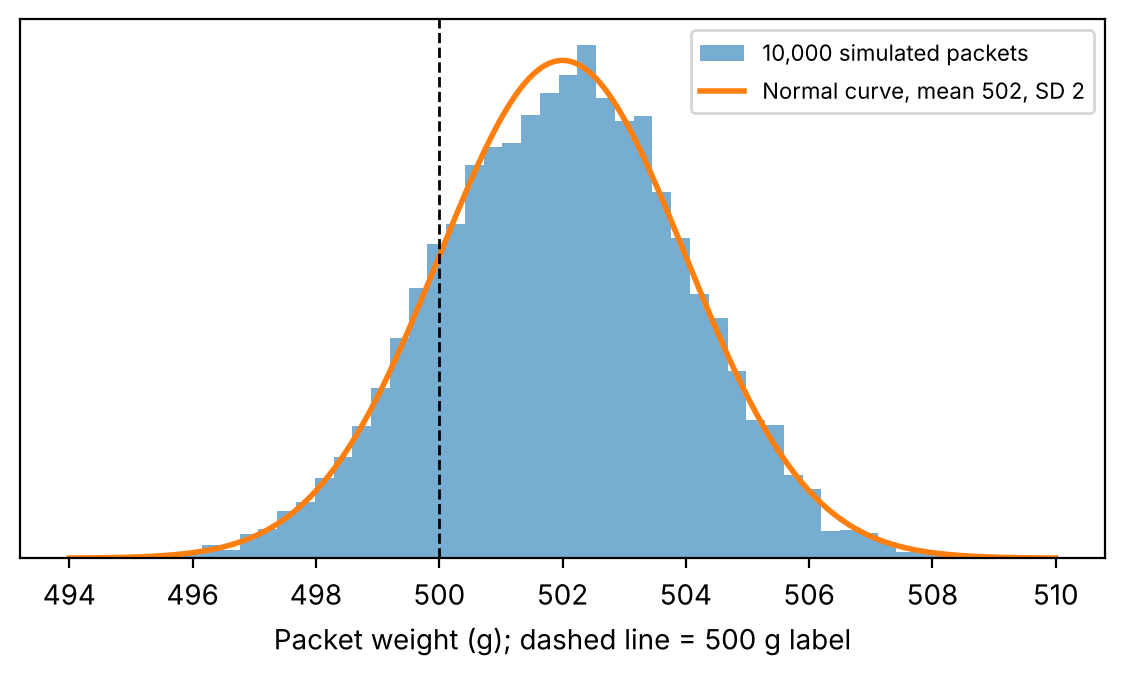

In [5]:
# Step 5. Histogram of the simulated weights with the normal curve on top
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(w, bins=50, density=True, color="tab:blue", alpha=0.6, label="10,000 simulated packets")
x = np.linspace(494, 510, 300)
ax.plot(x, stats.norm.pdf(x, 502, 2), color="tab:orange", lw=2, label="Normal curve, mean 502, SD 2")
ax.axvline(500, color="black", ls="--", lw=1)
ax.set_xlabel("Packet weight (g); dashed line = 500 g label")
ax.set_yticks([])
ax.legend(fontsize=8)
plt.show()

In [6]:
# Step 6. Real data: is S05's ordinary-day footfall close to normal?
url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
f = df[(df["store_id"] == "S05") & (df["is_festival"] == 0)]["footfall"]
m, sd = f.mean(), f.std()
print(f"S05 ordinary days: n = {len(f)}, mean {m:.1f}, SD {sd:.1f}, skewness {f.skew():.2f}")
for k, theory in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    print(f"Within {k} SD: {((f - m).abs() <= k * sd).mean():.4f}   (normal {theory})")

S05 ordinary days: n = 699, mean 1237.6, SD 224.3, skewness 0.57
Within 1 SD: 0.6738   (normal 0.6827)
Within 2 SD: 0.9614   (normal 0.9545)
Within 3 SD: 0.9957   (normal 0.9973)


In [7]:
# Step 7. z-scores: which ordinary days were most unusual for S05?
days = df[(df["store_id"] == "S05") & (df["is_festival"] == 0)].copy()
days["z"] = (days["footfall"] - m) / sd
cols = ["date", "day_of_week", "discount_pct", "rainfall_mm", "footfall", "z"]
top = days.sort_values("z", key=abs, ascending=False)[cols].head(5)
print(top.round({"rainfall_mm": 1, "z": 2}).to_string(index=False))
print(f"\nDays with |z| > 3: {(days['z'].abs() > 3).sum()} of {len(days)}")

      date day_of_week  discount_pct  rainfall_mm  footfall    z
2025-12-21      Sunday            15          0.0      2077 3.74
2025-12-28      Sunday            10          0.0      1983 3.32
2024-12-22      Sunday            10          0.0      1961 3.22
2024-12-08      Sunday             5          0.0      1889 2.90
2025-10-11    Saturday             5          0.0      1884 2.88

Days with |z| > 3: 3 of 699
